<a href="https://colab.research.google.com/github/shivanshu-web/Mini_Project/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
clean_df=pd.read_csv("/content/laptop_clean_dataset.csv")

In [3]:
clean_df.sample(5)

,Company,TypeName,Inches,Weight,screen_resolution,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price
621,Lenovo,Notebook,14.0,1.42,1366x768,HD,1.6,Intel,Celeron Dual Core N3060,0,0,32,2,windows,13266.7200
963,Dell,Notebook,14.0,1.6,1920x1080,Full HD,2.5,Intel,Core i5 7200U,128,0,0,8,windows,59620.3200
981,HP,Notebook,14.0,1.64,1920x1080,Full HD,2.5,Intel,Core i5 7200U,256,0,0,8,windows,55904.5728
1132,MSI,Gaming,14.0,1.7,1920x1080,Full HD,2.6,Intel,Core i7 6700HQ,256,1TB,0,16,windows,94252.3200
187,Dell,2 in 1 Convertible,13.3,1.62,1920x1080,Full HD,1.8,Intel,Core i7 8550U,0,1TB,0,8,windows,44701.9200


In [4]:
clean_df.shape

(1243, 15)

In [5]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Company            1243 non-null   object 
 1   TypeName           1243 non-null   object 
 2   Inches             1243 non-null   float64
 3   Weight             1243 non-null   object 
 4   screen_resolution  1243 non-null   object 
 5   display_type       1243 non-null   object 
 6   processor_speed    1243 non-null   float64
 7   processor_brand    1243 non-null   object 
 8   processor_type     1243 non-null   object 
 9   ssd_storage        1243 non-null   int64  
 10  hdd_storage        1243 non-null   object 
 11  flash_storage      1243 non-null   int64  
 12  ram                1243 non-null   int64  
 13  os                 1243 non-null   object 
 14  Price              1243 non-null   float64
dtypes: float64(3), int64(3), object(9)
memory usage: 145.8+ KB


In [6]:
clean_df.isnull().sum().sum()

np.int64(0)

In [7]:
clean_df['Weight'] = pd.to_numeric(clean_df['Weight'], errors='coerce')

In [8]:
clean_df['Weight'].dtype

dtype('float64')

In [9]:
clean_df[['Resolution_Width', 'Resolution_Height']] = (
    clean_df['screen_resolution']
    .str.extract(r'(\d+)\s*[xX]\s*(\d+)')
    .astype(int)
)

In [10]:
clean_df[
    ['screen_resolution', 'Resolution_Width', 'Resolution_Height']
].head()

,screen_resolution,Resolution_Width,Resolution_Height
0,2560x1600,2560,1600
1,1440x900,1440,900
2,1920x1080,1920,1080
3,2880x1800,2880,1800
4,2560x1600,2560,1600


In [11]:
clean_df.drop(columns=['screen_resolution'],inplace=True)

In [12]:
clean_df['hdd_storage'].value_counts(dropna=False)

,count
hdd_storage,
0,695
1TB,390
500,123
2TB,31
1TB 1TB,1
32,1
128,1
0TB,1


In [13]:
clean_df['hdd_storage'] = (
    clean_df['hdd_storage']
    .replace({
        '1TB': '1000',
        '2TB': '2000',
        '0TB': '0',
        '1TB 1TB': '2000'
    })
)

clean_df['hdd_storage'] = pd.to_numeric(
    clean_df['hdd_storage'],
    errors='coerce'
)

In [14]:
print(clean_df['hdd_storage'].dtype)
print(clean_df['hdd_storage'].value_counts(dropna=False))

int64
hdd_storage
0       696
1000    390
500     123
2000     32
32        1
128       1
Name: count, dtype: int64


In [15]:
clean_df.describe()

,Inches,Weight,processor_speed,ssd_storage,hdd_storage,flash_storage,ram,Price,Resolution_Width,Resolution_Height
count,1243.000000,1242.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000
mean,15.010218,2.061006,2.304489,172.788415,414.851167,4.492357,8.450523,60631.450094,1900.006436,1073.824618
std,1.448967,0.738233,0.503998,161.330647,519.231793,30.768612,5.116651,37429.117737,493.027552,283.822819
min,9.448819,0.690000,0.900000,0.000000,0.000000,0.000000,2.000000,9270.720000,1366.000000,768.000000
25%,14.000000,1.500000,2.000000,0.000000,0.000000,0.000000,4.000000,32687.280000,1920.000000,1080.000000
50%,15.600000,2.040000,2.500000,180.000000,0.000000,0.000000,8.000000,52693.920000,1920.000000,1080.000000
75%,15.600000,2.320000,2.700000,256.000000,1000.000000,0.000000,8.000000,79813.440000,1920.000000,1080.000000
max,18.400000,11.100000,3.600000,512.000000,2000.000000,512.000000,64.000000,324954.720000,3840.000000,2160.000000


In [16]:
clean_df.select_dtypes('object').describe()

,Company,TypeName,display_type,processor_brand,processor_type,os
count,1243,1243,1243,1243,1243,1243
unique,18,5,4,3,93,6
top,Dell,Notebook,Full HD,Intel,Core i5 7200U,windows
freq,281,711,835,1182,186,1075


In [17]:
cat_col=clean_df.select_dtypes('object').columns
num_col=clean_df.select_dtypes('number').columns

In [18]:
cat_col

Index(['Company', 'TypeName', 'display_type', 'processor_brand',
       'processor_type', 'os'],
      dtype='object')

In [19]:
num_col


Index(['Inches', 'Weight', 'processor_speed', 'ssd_storage', 'hdd_storage',
       'flash_storage', 'ram', 'Price', 'Resolution_Width',
       'Resolution_Height'],
      dtype='object')

In [20]:
clean_df.corr(numeric_only=True)["Price"].sort_values(ascending=False)

,Price
Price,1.000000
ram,0.739096
Resolution_Width,0.553224
ssd_storage,0.551168
Resolution_Height,0.549807
processor_speed,0.426237
Weight,0.204236
Inches,0.049907
flash_storage,-0.033705
hdd_storage,-0.096456


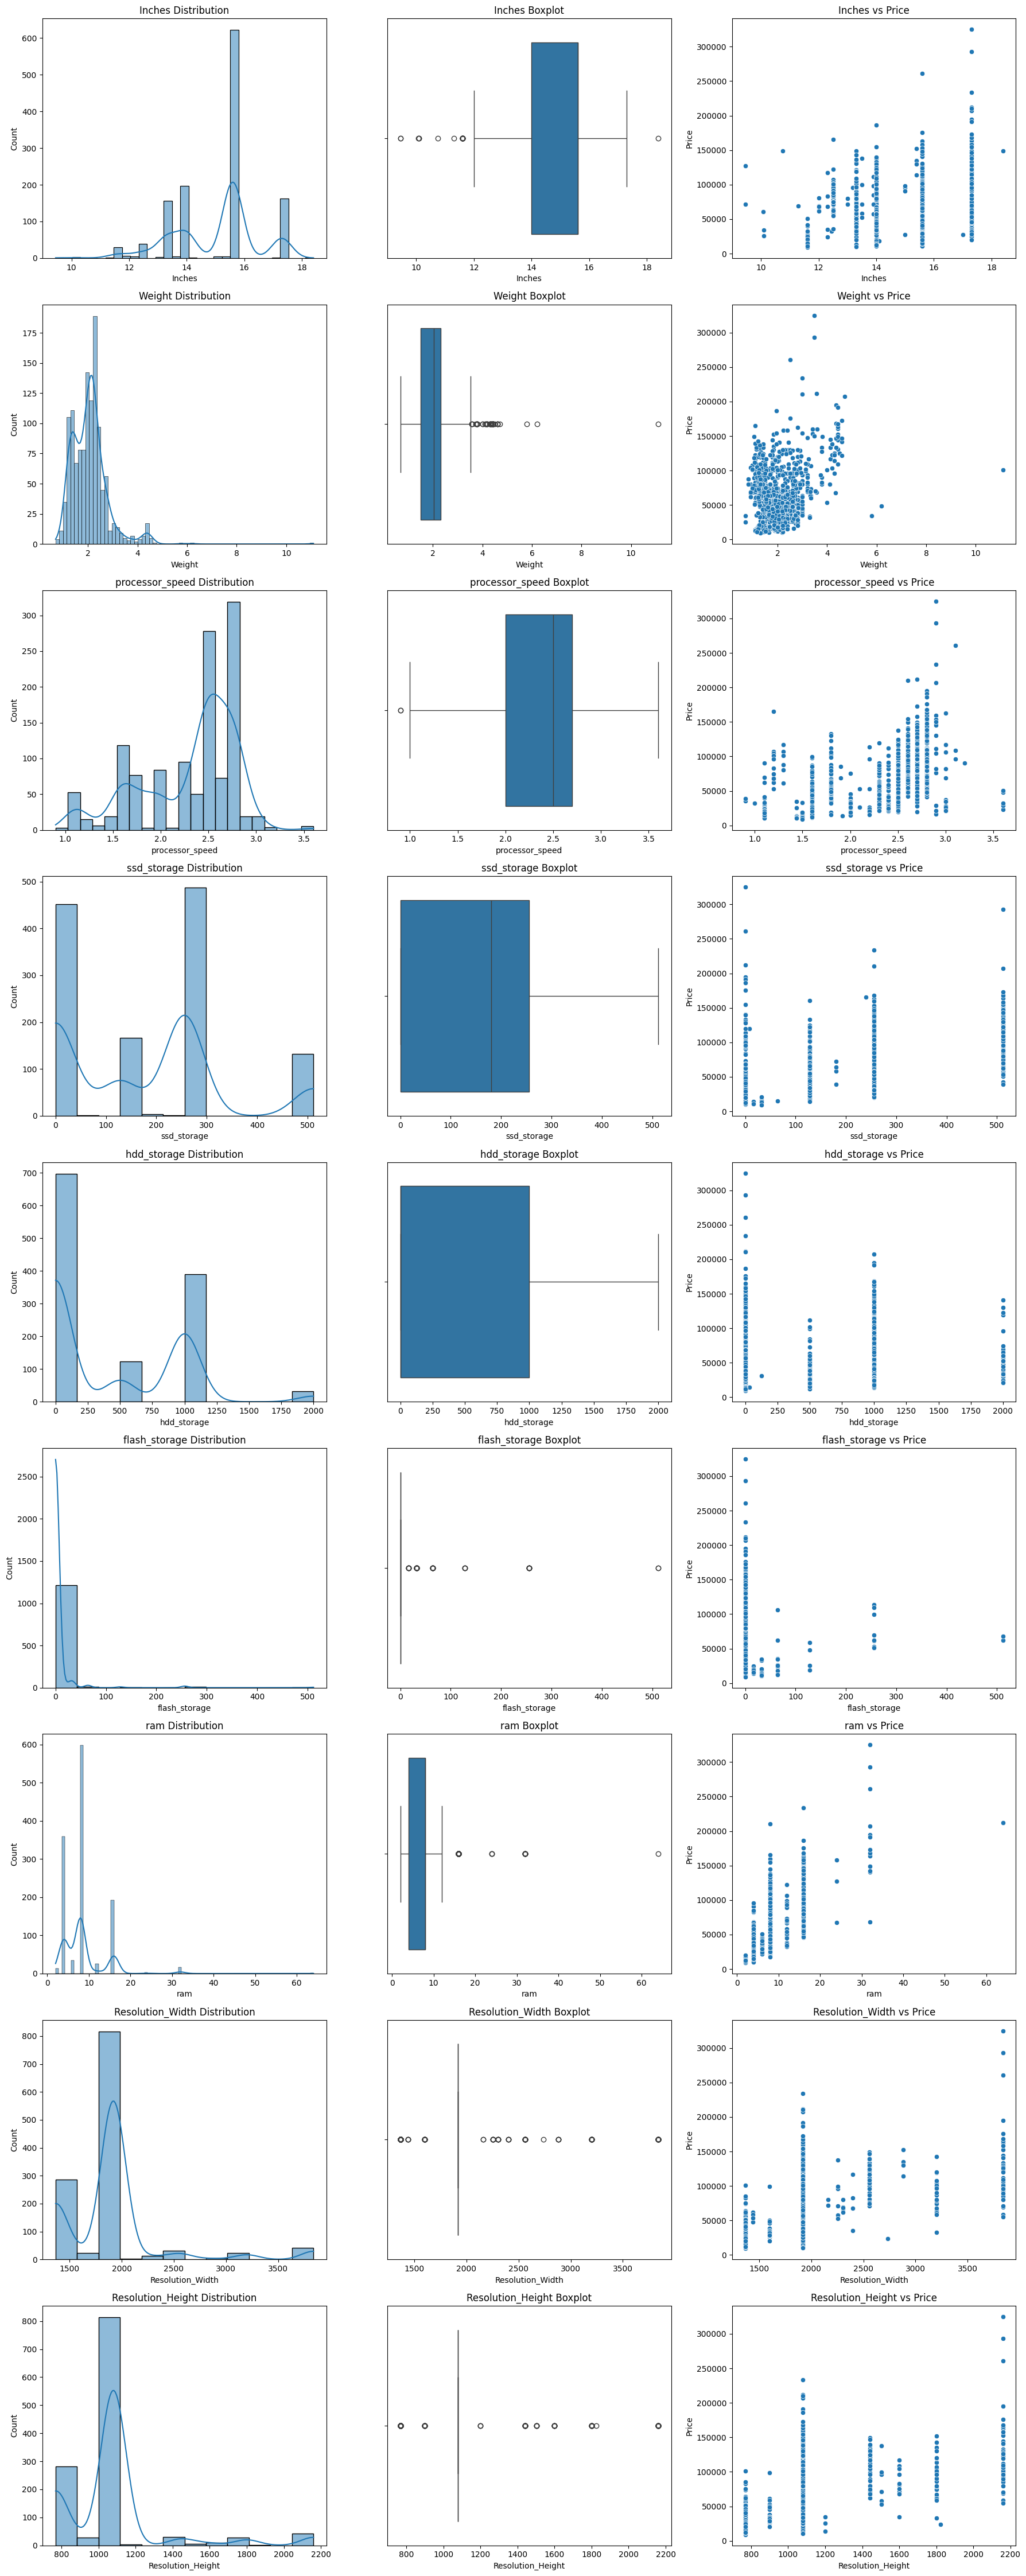

In [21]:
# sns.scatterplot(x=clean_df["ram"],y=clean_df["Price"])
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select numerical columns, excluding target
numer_cols = clean_df.select_dtypes(include='number').columns.drop('Price', errors='ignore')

# Create subplots
fig, axes = plt.subplots(
    len(numer_cols), 3,
    figsize=(18, 5 * len(numer_cols))
)

# Handle axes when there is only one numerical feature
axes = axes.reshape(len(numer_cols), 3)

for i, col in enumerate(numer_cols):

    # 1. Histogram
    sns.histplot(data=clean_df, x=col, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} Distribution')

    # 2. Boxplot
    sns.boxplot(data=clean_df, x=col, ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} Boxplot')

    # 3. Scatterplot with Price
    sns.scatterplot(data=clean_df, x=col, y='Price', ax=axes[i, 2])
    axes[i, 2].set_title(f'{col} vs Price')

plt.tight_layout()
plt.show()

In [22]:
clean_df[num_col].skew()

,0
Inches,-0.469638
Weight,2.573849
processor_speed,-0.847626
ssd_storage,0.596116
hdd_storage,0.898123
flash_storage,11.057739
ram,2.724098
Price,1.519041
Resolution_Width,2.214152
Resolution_Height,2.122366


In [23]:
print("Flash Storage:")
print(clean_df['flash_storage'].value_counts(dropna=False).sort_index())

print("\nWeight Summary:")
print(clean_df['Weight'].describe())

print("\nRAM Values:")
print(clean_df['ram'].value_counts(dropna=False).sort_index())

Flash Storage:
flash_storage
0      1175
16        7
32       35
64       12
128       4
256       8
512       2
Name: count, dtype: int64

Weight Summary:
count    1242.000000
mean        2.061006
std         0.738233
min         0.690000
25%         1.500000
50%         2.040000
75%         2.320000
max        11.100000
Name: Weight, dtype: float64

RAM Values:
ram
2      14
4     359
6      34
8     598
12     25
16    192
24      3
32     17
64      1
Name: count, dtype: int64


In [24]:
clean_df["Company"].value_counts(dropna=False)

,count
Company,
Dell,281
Lenovo,281
HP,260
Asus,149
Acer,105
MSI,53
Toshiba,47
Apple,21
Samsung,9


In [25]:
def brand(name):
  if name=='Lenovo':
       return 'Lenovo'
  elif name=='HP':
       return 'HP'
  elif name=='Dell':
       return 'Dell'
  elif name=='Acer':
       return 'Acer'
  elif name=='Apple':
      return 'Apple'
  elif name=='Asus':
      return 'Asus'
  elif name=='MSI':
      return 'MSI'
  elif name=='Toshiba':
      return 'Toshiba'
  else:
      return 'Other'

In [26]:
clean_df["Company"]=clean_df["Company"].apply(brand)

In [27]:
clean_df["Company"].value_counts(dropna=False)

,count
Company,
Dell,281
Lenovo,281
HP,260
Asus,149
Acer,105
MSI,53
Toshiba,47
Other,46
Apple,21


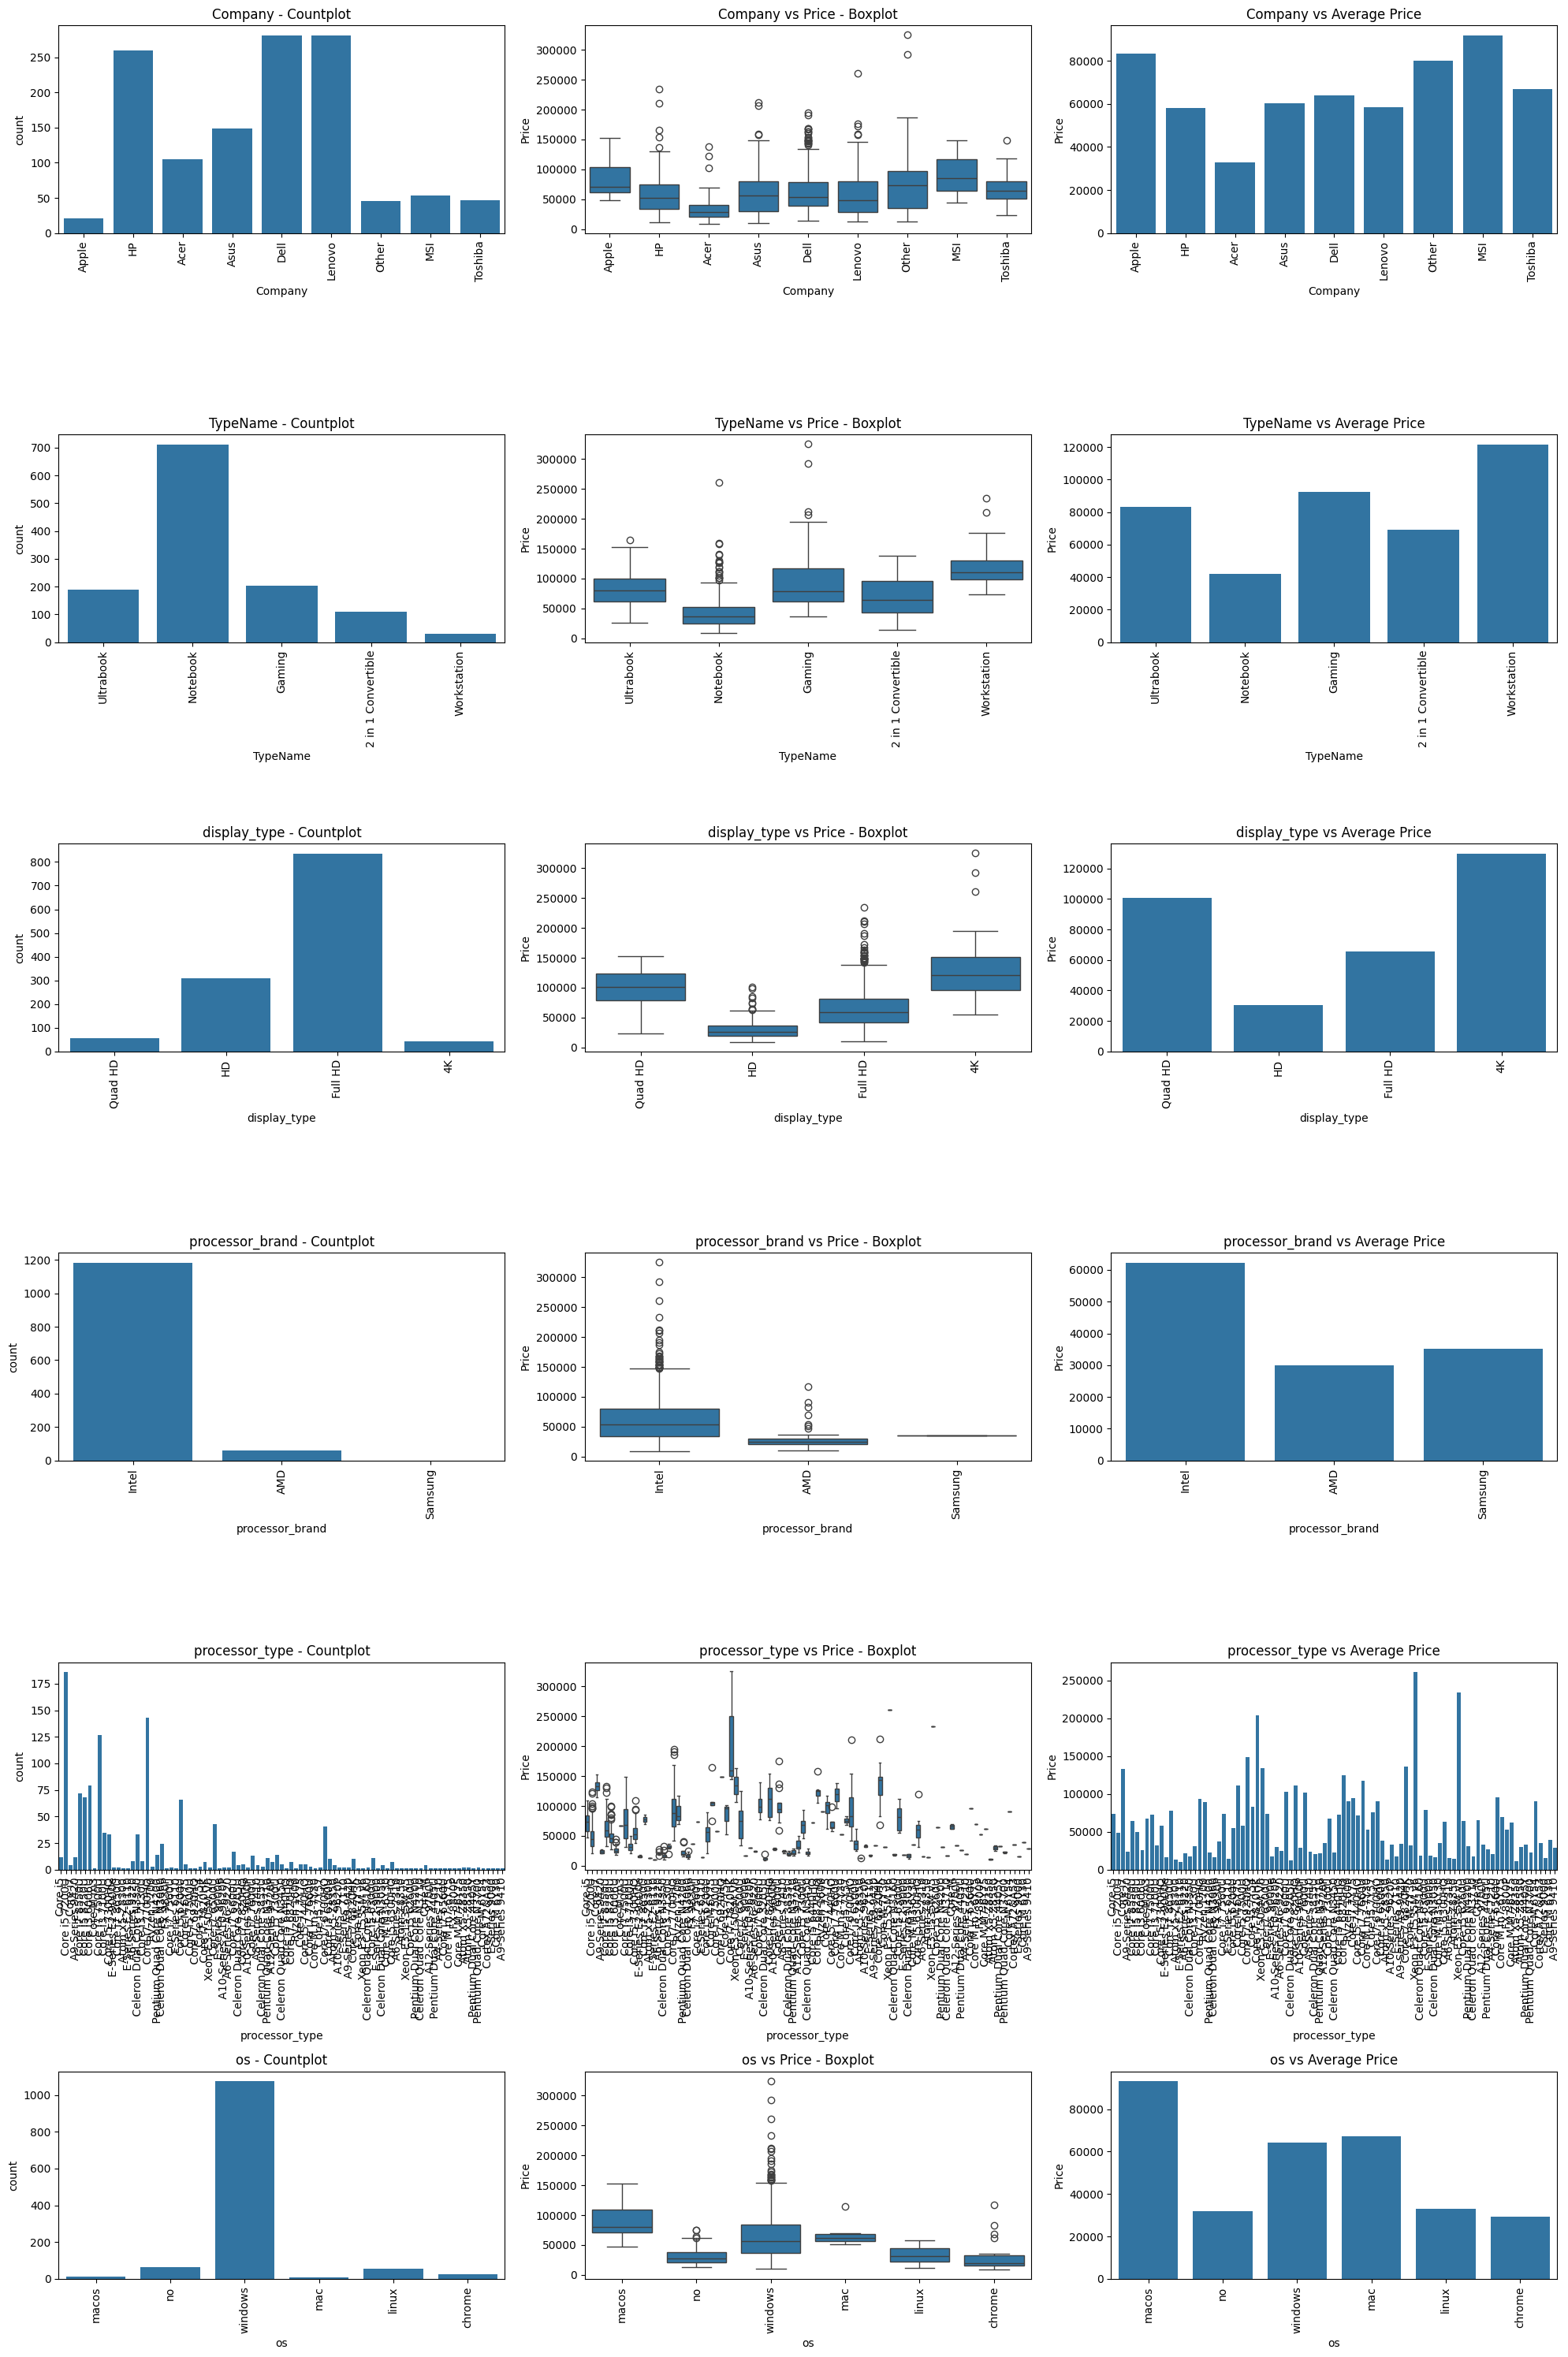

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select categorical columns
categorical_cols = clean_df.select_dtypes(
    include=['object', 'category']
).columns

# Subplots: rows = categorical columns, columns = 3 graphs
fig, axes = plt.subplots(
    len(categorical_cols), 3,
    figsize=(20, 5 * len(categorical_cols)),
    squeeze=False
)

for i, col in enumerate(categorical_cols):

    # 1. Countplot
    sns.countplot(data=clean_df, x=col, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} - Countplot')
    axes[i, 0].tick_params(axis='x', rotation=90)

    # 2. Boxplot: Category vs Price
    sns.boxplot(data=clean_df, x=col, y='Price', ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} vs Price - Boxplot')
    axes[i, 1].tick_params(axis='x', rotation=90)

    # 3. Barplot: Average Price per Category
    sns.barplot(data=clean_df, x=col, y='Price', errorbar=None, ax=axes[i, 2])
    axes[i, 2].set_title(f'{col} vs Average Price')
    axes[i, 2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [29]:
print("Missing Values:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows:")
print(clean_df.duplicated().sum())

print("\nDataset Shape:")
print(clean_df.shape)

Missing Values:
Company              0
TypeName             0
Inches               0
Weight               1
display_type         0
processor_speed      0
processor_brand      0
processor_type       0
ssd_storage          0
hdd_storage          0
flash_storage        0
ram                  0
os                   0
Price                0
Resolution_Width     0
Resolution_Height    0
dtype: int64

Duplicate Rows:
1

Dataset Shape:
(1243, 16)


In [30]:
# Missing values
print("Missing values:")
print(clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

# Duplicate rows
print("\nNumber of duplicate rows:")
print(clean_df.duplicated().sum())

# Weight distribution summary
print("\nWeight summary:")
print(clean_df["Weight"].describe())

# Flash storage values
print("\nFlash storage value counts:")
print(clean_df["flash_storage"].value_counts().sort_index())

# HDD storage values
print("\nHDD storage value counts:")
print(clean_df["hdd_storage"].value_counts().sort_index())

Missing values:
Weight    1
dtype: int64

Number of duplicate rows:
1

Weight summary:
count    1242.000000
mean        2.061006
std         0.738233
min         0.690000
25%         1.500000
50%         2.040000
75%         2.320000
max        11.100000
Name: Weight, dtype: float64

Flash storage value counts:
flash_storage
0      1175
16        7
32       35
64       12
128       4
256       8
512       2
Name: count, dtype: int64

HDD storage value counts:
hdd_storage
0       696
32        1
128       1
500     123
1000    390
2000     32
Name: count, dtype: int64


In [31]:
# Find the row where Weight is missing
missing_weight = clean_df[clean_df["Weight"].isnull()]

display(missing_weight)

,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,Resolution_Width,Resolution_Height
201,Dell,Ultrabook,13.3,NaN,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,77202.72,1920,1080


In [32]:
clean_df[(clean_df["Company"] == "Dell") & (clean_df["TypeName"] == "Ultrabook")& (clean_df["Inches"] == 13.3) ]


,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,Resolution_Width,Resolution_Height
19,Dell,Ultrabook,13.3,1.22,Full HD,1.6,Intel,Core i5 8250U,128,0,0,8,windows,52161.1200,1920,1080
32,Dell,Ultrabook,13.3,1.20,Quad HD,1.8,Intel,Core i7 8550U,512,0,0,16,windows,99580.3200,3200,1800
68,Dell,Ultrabook,13.3,1.40,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,50882.4000,1920,1080
86,Dell,Ultrabook,13.3,1.21,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,87858.7200,1920,1080
108,Dell,Ultrabook,13.3,1.23,Quad HD,2.4,Intel,Core i7 7560U,256,0,0,8,windows,73473.1200,3200,1800
111,Dell,Ultrabook,13.3,1.21,Full HD,1.6,Intel,Core i5 8250U,256,0,0,8,windows,86793.1200,1920,1080
175,Dell,Ultrabook,13.3,1.23,Full HD,1.6,Intel,Core i5 8250U,256,0,0,8,windows,74538.7200,1920,1080
200,Dell,Ultrabook,13.3,1.21,4K,1.8,Intel,Core i7 8550U,256,0,0,8,windows,103842.7200,3840,2160
201,Dell,Ultrabook,13.3,NaN,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,77202.7200,1920,1080
207,Dell,Ultrabook,13.3,1.40,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,49650.5664,1920,1080


In [33]:
similar_laptops = clean_df[
    (clean_df["Company"] == "Dell") &
    (clean_df["TypeName"] == "Ultrabook") &
    (clean_df["Inches"] == 13.3) &
    (clean_df["processor_type"] == "Core i7 8550U") &
    (clean_df["ssd_storage"] == 256) &
    (clean_df["ram"] == 8)
]

print("Matching laptops:", len(similar_laptops))
print("Median Weight:", similar_laptops["Weight"].median())
print("Mean Weight:", similar_laptops["Weight"].mean())

Matching laptops: 0
Median Weight: nan
Mean Weight: nan


In [34]:
similar_laptops = clean_df[
    (clean_df["Company"] == "Dell") &
    (clean_df["TypeName"] == "Ultrabook") &
    (clean_df["Inches"] == 13.3) &
    (clean_df["processor_type"].str.strip() == "Core i7 8550U") &
    (clean_df["ssd_storage"] == 256) &
    (clean_df["ram"] == 8)
]

print("Matching laptops:", len(similar_laptops))
print("\nWeights:")
print(similar_laptops["Weight"].sort_values().to_list())

print("\nGroup Median:", similar_laptops["Weight"].median())
print("Overall Median:", clean_df["Weight"].median())

Matching laptops: 7

Weights:
[1.2, 1.2, 1.21, 1.21, 1.4, 1.4, nan]

Group Median: 1.21
Overall Median: 2.04


In [35]:
clean_df.loc[201, "Weight"] = similar_laptops["Weight"].median()

print("Weight at index 201:", clean_df.loc[201, "Weight"])
print("Missing Weight values:", clean_df["Weight"].isnull().sum())

Weight at index 201: 1.21
Missing Weight values: 0


In [36]:
# Count duplicate rows
print("Duplicate rows:", clean_df.duplicated().sum())

# Display duplicate rows
display(clean_df[clean_df.duplicated(keep=False)])

Duplicate rows: 1


,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,Resolution_Width,Resolution_Height
955,Toshiba,Notebook,13.3,1.2,Full HD,2.3,Intel,Core i5 6200U,128,0,0,4,windows,63669.6,1920,1080
977,Toshiba,Notebook,13.3,1.2,Full HD,2.3,Intel,Core i5 6200U,128,0,0,4,windows,63669.6,1920,1080


In [37]:
# Keep the first occurrence and remove duplicate rows
clean_df = clean_df.drop_duplicates(keep="first")

# Verify duplicates are removed
print("Duplicate rows remaining:", clean_df.duplicated().sum())
print("Dataset shape:", clean_df.shape)


Duplicate rows remaining: 0
Dataset shape: (1242, 16)


In [38]:
# Find the laptop with the maximum weight
display(
    clean_df[clean_df["Weight"] == clean_df["Weight"].max()]
)

# Check the weight distribution
print(clean_df["Weight"].describe())

,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,Resolution_Width,Resolution_Height
614,Asus,Ultrabook,14.0,11.1,Full HD,2.7,Intel,Core i7 7500U,512,0,0,16,windows,101232.0,1920,1080


count    1242.000000
mean        2.061014
std         0.738224
min         0.690000
25%         1.500000
50%         2.040000
75%         2.320000
max        11.100000
Name: Weight, dtype: float64


In [39]:
# Display laptops weighing more than 5 kg
display(
    clean_df[clean_df["Weight"] > 5]
)

,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,Resolution_Width,Resolution_Height
293,Lenovo,Notebook,17.3,5.8,HD,2.5,Intel,Core i5 7200U,0,1000,0,6,windows,34578.72,1600,900
614,Asus,Ultrabook,14.0,11.1,Full HD,2.7,Intel,Core i7 7500U,512,0,0,16,windows,101232.00,1920,1080
640,Dell,Notebook,15.6,6.2,Full HD,1.8,Intel,Core i7 8550U,256,0,0,8,windows,48964.32,1920,1080


In [40]:
clean_df["ppi"]=(clean_df['Resolution_Width']**2+clean_df["Resolution_Height"]**2)**0.5/clean_df["Inches"]

In [41]:
clean_df.drop(columns=["Resolution_Width","Resolution_Height"],inplace=True)

In [42]:
clean_df.sample(5)

,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,hdd_storage,flash_storage,ram,os,Price,ppi
172,Lenovo,Notebook,15.6,1.90,Full HD,2.5,Intel,Core i5 7200U,128,1000,0,8,windows,43316.64,141.211998
987,HP,Notebook,13.3,1.49,HD,2.4,Intel,Core i3 7100U,0,500,0,4,windows,42624.00,117.826530
953,Asus,Gaming,17.3,2.99,Full HD,2.8,Intel,Core i7 7700HQ,256,1000,0,16,windows,93186.72,127.335675
1184,Asus,Gaming,17.3,2.90,Full HD,2.8,Intel,Core i7 7700HQ,256,1000,0,16,windows,103842.72,127.335675
665,Dell,Gaming,15.6,3.21,Full HD,2.5,Intel,Core i5 7300HQ,128,1000,0,16,windows,109277.28,141.211998


In [43]:
display(clean_df["flash_storage"].value_counts())
display(clean_df["hdd_storage"].value_counts())


,count
flash_storage,
0,1174
32,35
64,12
256,8
16,7
128,4
512,2


,count
hdd_storage,
0,695
1000,390
500,123
2000,32
32,1
128,1


In [44]:
corr=clean_df.corr(numeric_only=True)["Price"]
corr[["flash_storage","hdd_storage"]]

,Price
flash_storage,-0.033696
hdd_storage,-0.096428


In [45]:
clean_df.drop(columns=["flash_storage","hdd_storage"],inplace=True)

In [46]:
clean_df.sample(5)

,Company,TypeName,Inches,Weight,display_type,processor_speed,processor_brand,processor_type,ssd_storage,ram,os,Price,ppi
1157,Dell,2 in 1 Convertible,15.6,2.09,Full HD,2.7,Intel,Core i7 7500U,512,16,windows,62817.12,141.211998
1187,Lenovo,Notebook,17.3,2.80,HD,2.5,Intel,Core i5 7200U,0,8,no,28717.92,106.113062
1119,HP,Notebook,15.6,1.88,Full HD,2.3,Intel,Core i5 6200U,256,8,windows,84129.12,141.211998
135,Acer,Notebook,17.3,3.00,Full HD,2.7,Intel,Core i3 7130U,0,4,windows,34898.40,127.335675
456,Dell,Notebook,15.6,2.02,Full HD,1.6,Intel,Core i5 8250U,0,8,windows,40439.52,141.211998


In [47]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

num_cols = clean_df.select_dtypes(include=np.number).columns

# Log transformation
log_transformer = FunctionTransformer(np.log1p)

clean_df[num_cols] = log_transformer.fit_transform(clean_df[num_cols])

In [48]:
# Features: Price ko chhodkar baaki sabhi columns
X = clean_df.drop("Price", axis=1)

# Target: Sirf Price column
y = clean_df["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget sample:")
print(y.head())

Features shape: (1242, 12)
Target shape: (1242,)

Feature columns:
['Company', 'TypeName', 'Inches', 'Weight', 'display_type', 'processor_speed', 'processor_brand', 'processor_type', 'ssd_storage', 'ram', 'os', 'ppi']

Target sample:
0    11.175769
1    10.776798
2    10.329964
3    11.814483
4    11.473111
Name: Price, dtype: float64


In [49]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check the shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (993, 12)
X_test: (249, 12)
y_train: (993,)
y_test: (249,)


In [50]:
# Numerical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical features
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numeric_features))
print("Total categorical features:", len(categorical_features))

Numerical features:
['Inches', 'Weight', 'processor_speed', 'ssd_storage', 'ram', 'ppi']

Categorical features:
['Company', 'TypeName', 'display_type', 'processor_brand', 'processor_type', 'os']

Total numerical features: 6
Total categorical features: 6


In [51]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])



categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])




preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)




model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])



model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_pred_train=model.predict(X_train)

mae_t = mean_absolute_error(y_train, y_pred_train)

rmse_t = np.sqrt(
    mean_squared_error(y_train, y_pred_train)
)

r2_t = r2_score(y_train, y_pred_train)
print("\n Baselin Linear Regression Results on training data")
print("-------------------------")
print(f"MAE  : {mae_t:.2f}")
print(f"RMSE : {rmse_t:.2f}")
print(f"R2   : {r2_t:.4f}")
#

# 10. Evaluate the Model


mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)


# 11. Display Results


print("\n Baselin Linear Regression Results")
print("-------------------------")

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")


 Baselin Linear Regression Results on training data
-------------------------
MAE  : 0.16
RMSE : 0.21
R2   : 0.8831

 Baselin Linear Regression Results
-------------------------
MAE  : 0.19
RMSE : 0.26
R2   : 0.8072


In [52]:
import pandas as pd
import numpy as np

# Actual and predicted prices
results_df = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
}, index=y_test.index)

# Calculate absolute error
results_df["Absolute_Error"] = np.abs(
    results_df["Actual_Price"] - results_df["Predicted_Price"]
)

# Show sample predictions
print("Sample predictions:")
print(results_df.head(10).round(2))

# Show 10 predictions with the largest errors
print("\n10 predictions with the largest errors:")
print(
    results_df.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10).round(2)
)

Sample predictions:
      Actual_Price  Predicted_Price  Absolute_Error
900          11.48            11.02            0.47
1004          9.99             9.96            0.03
671          10.32            10.18            0.14
620          11.51            11.21            0.30
926          11.46            11.42            0.03
998          11.33            10.91            0.42
745          10.13             9.96            0.17
938          11.47            11.38            0.09
451          10.59            10.67            0.08
439          10.35            10.79            0.43

10 predictions with the largest errors:
      Actual_Price  Predicted_Price  Absolute_Error
700           9.56            10.52            0.96
424          11.41            10.46            0.96
597          12.47            11.54            0.93
551          11.98            11.21            0.77
23           10.47            11.19            0.72
1107         12.26            11.54            0.71
746

In [53]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -----------------------------------
# 1. Numerical preprocessing
# -----------------------------------

rf_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


# -----------------------------------
# 2. Categorical preprocessing
# -----------------------------------

rf_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# -----------------------------------
# 3. Combine preprocessing
# -----------------------------------

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", rf_numeric_transformer, numeric_features),
        ("cat", rf_categorical_transformer, categorical_features)
    ]
)


# -----------------------------------
# 4. Create complete pipeline
# -----------------------------------

rf_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])


# -----------------------------------
# 5. Train the model
# -----------------------------------

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# -----------------------------------
# 6. Make predictions
# -----------------------------------

rf_pred = rf_model.predict(X_test)


# -----------------------------------
# 7. Evaluate the model
# -----------------------------------

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)


# -----------------------------------
# 8. Compare both models
# -----------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        rf_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        rf_rmse
    ],
    "R2": [
        r2_score(y_test, y_pred),
        rf_r2
    ]
})

display(comparison.round(4))

Random Forest training completed!


,Model,MAE,RMSE,R2
0,Linear Regression,0.1925,0.2578,0.8072
1,Random Forest,0.1741,0.2405,0.8323


In [54]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Predictions on training data
rf_train_pred = rf_model.predict(X_train)

# 2. Calculate training metrics
train_mae = mean_absolute_error(y_train, rf_train_pred)

train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_pred)
)

train_r2 = r2_score(y_train, rf_train_pred)


# 3. Calculate testing metrics
test_mae = mean_absolute_error(y_test, rf_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

test_r2 = r2_score(y_test, rf_pred)


# 4. Compare performance
import pandas as pd

performance_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Training": [train_mae, train_rmse, train_r2],
    "Testing": [test_mae, test_rmse, test_r2]
})

display(performance_comparison.round(4))

,Metric,Training,Testing
0,MAE,0.0641,0.1741
1,RMSE,0.0846,0.2405
2,R2,0.9817,0.8323


In [55]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score,mean_squared_error

ridge_model=Pipeline(steps=[
("processor",preprocessor),
("regressor",Ridge(alpha=10.0))
])
ridge_model.fit(X_train,y_train)
ridge_pred=ridge_model.predict(X_test)


print("Ridge MAE:", mean_absolute_error(y_test, ridge_pred))
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("Ridge R2:", r2_score(y_test, ridge_pred))


Ridge MAE: 0.20860855109897694
Ridge RMSE: 0.2730816260773481
Ridge R2: 0.7837454508470746


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Ridge pipeline
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Alpha values to test
param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 50, 100, 200]
}

# Search using training data only
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Alpha:", ridge_search.best_params_["regressor__alpha"])
print("Best CV MAE:", -ridge_search.best_score_)

# Evaluate the best model on test data
best_ridge = ridge_search.best_estimator_
ridge_pred_tuned = best_ridge.predict(X_test)

print("\nTuned Ridge Results")
print("-------------------")
print("MAE:", mean_absolute_error(y_test, ridge_pred_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred_tuned)))
print("R2:", r2_score(y_test, ridge_pred_tuned))

Best Alpha: 0.1
Best CV MAE: 0.18949734612058777

Tuned Ridge Results
-------------------
MAE: 0.19226199126698246
RMSE: 0.25672810050567896
R2: 0.8088707715084693


In [57]:
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify categorical and numerical columns
cat_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns

num_cols = X_train.select_dtypes(
    include=np.number
).columns

# Encode categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', 'passthrough', num_cols)
    ]
)

# Create pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

# Hyperparameter grid
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [0.5, 1.0]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=2
)

# Train
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best Parameters: {'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV MAE: 0.16687044600621082


In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = best_model.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R2:", r2_score(y_test, y_pred))

Test MAE: 0.17027120645088675
Test RMSE: 0.23035838552266266
Test R2: 0.846117815156757
